# 01 · The platform's classes and yearly change at 100 m

**Question:** is the platform's 100 m class a fair label, and do the maps change as much from year to year at 100 m as at 250 m?

The platform runs land use at 100 m: it reads Esri's 10 m land cover from Earth Engine at 100 m and takes one class per cell. Our land-use experiments were made at 250 m. Before moving them, this notebook checks the label they learn from and score against.

| Input | Per cell | Where |
|---|---|---|
| `esri_2017` … `esri_2025` | `class`: the platform's class, as Earth Engine returns it at 100 m; the share of the cell's 10 m pixels in each class | Shared 100 m store (`data_100m_tools/grid100.py`) |
| `ESRI_LULC_2017` … `2025` | The class at 250 m, as the 250 m experiments used it | `landuse_experiments/data/esri/` |

Both grids are cut to the cells whose centre is inside Guinea, as the platform's boundary mask does. Computations are in `scripts/classes100.py`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import classes100 as C
G, H = C.G, C.H

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30, "display.width", 200)

## 1 · The store

In [2]:
manifest = pd.DataFrame(G.layers()).T
manifest = manifest[manifest.group == "landcover"]
manifest["MB"] = [round((G.STORE / f).stat().st_size / 1e6, 1) for f in manifest.file]
print(f"{G.cells().size:,} cells inside Guinea; codes: {manifest.notes.iloc[0]}")
manifest[["columns", "dtype", "MB"]]

25,067,269 cells inside Guinea; codes: class: Esri code (1 water, 2 trees, 4 flooded vegetation, 5 crops, 7 built area, 8 bare ground, 10 clouds, 11 rangeland; 0 no data); other columns: share of the cell in that class (%)


,columns,dtype,MB
esri_2017,"[class, water, trees, flooded_vegetation, crop...",uint8,27.7
esri_2018,"[class, water, trees, flooded_vegetation, crop...",uint8,28.1
esri_2019,"[class, water, trees, flooded_vegetation, crop...",uint8,29.1
esri_2020,"[class, water, trees, flooded_vegetation, crop...",uint8,28.6
esri_2021,"[class, water, trees, flooded_vegetation, crop...",uint8,29.1
esri_2022,"[class, water, trees, flooded_vegetation, crop...",uint8,28.4
esri_2023,"[class, water, trees, flooded_vegetation, crop...",uint8,29.3
esri_2024,"[class, water, trees, flooded_vegetation, crop...",uint8,29.0
esri_2025,"[class, water, trees, flooded_vegetation, crop...",uint8,29.0
glclu_2010,"[cropland, trees5m, regrown]",uint8,12.5


## 2 · The platform's class against the 10 m pixels

For each cell, the platform's class against the class that holds most of the cell's 10 m pixels (the majority of the shares). Also: how much of the cell is in the platform's class, and how many cells have no class above half (truly mixed cells).

In [3]:
purity = C.save("01_class_vs_shares.csv", C.class_against_shares())
purity.round(2)

,class = majority (%),"cell in its own class (%, mean)","largest share (%, mean)",cells with no class above half (%),no data or clouds (cells)
year,,,,,
2017,94.74,92.33,94.26,0.35,35
2018,94.66,92.23,94.19,0.35,0
2019,94.41,91.89,93.95,0.36,0
2020,94.50,92.03,94.06,0.36,41
2021,94.41,91.87,93.93,0.37,47
2022,94.57,92.11,94.11,0.36,0
2023,94.35,91.81,93.89,0.38,15
2024,94.43,91.92,93.97,0.38,0
2025,94.43,91.91,93.96,0.39,0


In [4]:
# Rows: the platform's class in 2024; columns: the majority of the shares; % of each row
C.confusion_against_majority(2024).round(1)

majority of the shares,Water,Trees,Flooded vegetation,Crops,Built area,Bare ground,Rangeland
platform class,,,,,,,
Water,83.9,7.4,2.3,0.5,0.2,0.4,5.4
Trees,0.1,95.2,0.0,0.1,0.1,0.0,4.6
Flooded vegetation,1.3,3.1,93.8,0.2,0.1,0.0,1.5
Crops,0.1,2.2,0.1,90.9,0.4,0.0,6.2
Built area,0.0,3.4,0.1,0.4,92.0,0.0,4.1
Bare ground,9.3,0.4,0.2,0.9,0.5,82.4,6.4
Rangeland,0.1,5.7,0.0,0.2,0.1,0.0,93.9


**Reading:**

* **The platform's class is the majority of the 10 m pixels in 94.4–94.7 % of the cells**, every year. On average 92 % of a cell is in its platform class.
* **Truly mixed cells are rare:** 0.4 % of the cells have no class covering more than half. Guinea's land cover comes in patches larger than 100 m.
* **The 5.5 % of cells that differ sit on edges between classes.** Water cells are partly trees or rangeland (riverbanks), and bare-ground cells are partly water (sand bars). The platform's class is not an exact majority, most likely because Earth Engine reads a 10 m layer at 100 m from a coarser level of its pre-computed image pyramid, with a nearest-neighbour pick, rather than from all 100 pixels (Google Earth Engine, *Scale* guide).
* So the platform's class is a fair label for the model. Where a cell is split, the shares say how.

## 3 · Class areas

The area of each class in 2024: from the shares (the 10 m pixels, the true Esri area), from one class per 100 m cell (the platform's class, and the majority), and from one class per 250 m cell.

In [5]:
areas = C.save("01_class_areas_2024.csv", C.class_areas(2024))
print(f"100 m and 250 m maps give the same class at a 100 m cell's centre in {C.agreement_100_250(2024):.1f} % of the cells (2024)")
areas.round(1)

100 m and 250 m maps give the same class at a 100 m cell's centre in 86.5 % of the cells (2024)


,10 m pixels (shares),"100 m, platform class","100 m, majority of the shares","250 m, class","100 m, platform class vs 10 m (%)","100 m, majority of the shares vs 10 m (%)","250 m, class vs 10 m (%)"
Water,1384.7,1387.8,1360.2,1379.6,0.2,-1.8,-0.4
Trees,128946.7,129156.0,129436.8,129715.9,0.2,0.4,0.6
Flooded vegetation,1798.9,1798.8,1808.4,1806.1,-0.0,0.5,0.4
Crops,3329.7,3292.4,3275.0,3205.2,-1.1,-1.6,-3.7
Built area,2806.8,2777.5,2776.4,2709.5,-1.0,-1.1,-3.5
Bare ground,63.5,60.8,60.2,55.4,-4.2,-5.2,-12.7
Rangeland,108142.9,108000.1,107756.3,107596.2,-0.1,-0.4,-0.5


**Reading:**

* **One class per 100 m cell gives the large classes within 0.2 %** of their 10 m area (trees, rangeland, water, flooded vegetation).
* **Small, scattered classes lose area, less at 100 m than at 250 m:** crops −1.1 % against −3.7 %, built area −1.0 % against −3.5 %, bare ground −4.2 % against −12.7 %. A class that rarely fills most of a cell is undercounted; this is the known majority-rule bias of coarse land-cover maps (Moody & Woodcock 1994).
* **The shares give the 10 m area exactly**, so reported class areas should come from them, as the deforestation work does for forest (`deforestation_experiments/1_areas/02_reporting_areas`).
* **The 100 m and 250 m maps agree in 86.5 % of the cells.** The 100 m map is not the 250 m map made finer, so a score at 100 m is not comparable with one at 250 m. Methods are compared on the same grid.

## 4 · Change from year to year

For each pair of years: the share of Guinea whose class changes, on each grid. Of that change, the share into a class the cell had not held in any earlier map since 2017 (*new*, as the 250 m notebook 11 counts it) and the share that goes back to the start class the next year (a flip). The last column is the least share of the land whose 10 m pixels changed, from the shares: half the sum of the absolute changes of the eight shares in each cell. Changes that cancel inside a cell are not seen, so it is a floor.

In [6]:
change = C.save("01_change_by_year.csv", C.change_table())
change.round(1)

250 m                                                            100 m                                                   100 m majority                                \
          changed (% of area) of it, back the next year (%) of it, new (%) changed (% of area) of it, back the next year (%) of it, new (%) changed (% of area) of it, back the next year (%)   
from to                                                                                                                                                                                         
2017 2018                14.7                          25.2            NaN                14.5                          25.5            NaN                14.5                          25.2   
2018 2019                11.3                          38.8           67.2                11.3                          38.5           67.2                11.1                          38.4   
2019 2020                10.9                          31.9           33.7                10.9                          31.7           34.5                10.8                          31.5   
2020 2021                 9.7                          38.1           34.8                 9.7                          37.8           35.2                 9.6                          37.7   
2021 2022                10.5                          35.4           30.6                10.5                          35.3           30.8                10.3                          35.2   
2022 2023                10.3                          38.0           27.3                10.4                          38.0           27.6                10.3                          37.7   
2023 2024                10.7                          41.6           26.2                10.7                          41.0           26.3                10.6                          41.1   
2024 2025                12.6                           NaN           18.5                12.6                           NaN           18.9                12.5                           NaN   

                                        10 m shares  
          of it, new (%) changed (% of area), floor  
from to                                              
2017 2018            NaN                       14.3  
2018 2019           67.3                       11.1  
2019 2020           34.3                       10.7  
2020 2021           35.2                        9.5  
2021 2022           31.0                       10.3  
2022 2023           27.6                       10.2  
2023 2024           26.6                       10.5  
2024 2025           18.8                       12.4

In [7]:
# 2024 -> 2025: how much of a 100 m cell's 10 m pixels changed, when its class changed and when it did not
C.save("01_change_depth_2024_2025.csv", C.change_depth()).round(1)

,cells (%),"10 m pixels changed (% of the cell, median)",cells with more than half changed (%),cells with under a tenth changed (%),share of all changed 10 m pixels (%)
class changed,12.6,66.0,63.1,5.7,63.2
class kept,87.4,0.0,2.0,83.7,36.8


**Reading:**

* **Maps change as much at 100 m as at 250 m:** 9.7–14.7 % of Guinea a year on both grids, within 0.15 point. The majority label gives the same.
* **The 10 m pixels change about as much:** at least 9.5–14.3 % a year from the shares. The flicker is in Esri's annual maps, not in the grid. Finer cells neither add nor remove it.
* **Flips are the same on both grids:** 25–42 % of each year's change goes back the next year, and only 18–35 % of it is into a class new to the cell (from 2019→2020, when there are at least two earlier maps). Esri's series alternates (Pontius et al. 2017) whatever the cell size.
* **A change of class is mostly a real change of the cell.** Where the class changed (12.6 % of cells in 2024→2025), a median 66 % of the cell's 10 m pixels changed, and in 63 % of these cells more than half did. Where the class stayed, the median cell did not change at all. Yet a third of all changed 10 m pixels (37 %) lie in cells that kept their class: one class per cell does not see them, the shares do.
* So the flip-back check stays as it is at 100 m (README).

## 5 · The observed amount of change, 2024 → 2025

The amount of each transition between the 2024 and 2025 maps, on each grid. This is the observed amount used to compare methods (each method places the same amount, so only where it puts change counts). The deployed notebook, which our 250 m rebuild of the method follows, models a transition only if it has at least 1,000 pixels (`select_significant_transitions`, `MIN_CHANGE_PIXELS_LAND_USE`): 1,000 ha at 100 m, 6,250 ha at 250 m. The platform's backend on `main` does not apply that rule: it trains every transition that occurs and has at least 10 samples (notebook 02).

In [8]:
trans = C.save("01_transitions_2024_2025.csv", C.transitions())
print(f"Changed: {trans['100 m km²'].sum():,.0f} km² at 100 m, {trans['250 m km²'].sum():,.0f} km² at 250 m; "
      f"transitions with 1,000 pixels or more: {int(trans['100 m passes'].sum())} at 100 m, {int(trans['250 m passes'].sum())} at 250 m")
trans[trans["100 m passes"]].round(1)

Changed: 31,153 km² at 100 m, 31,173 km² at 250 m; transitions with 1,000 pixels or more: 23 at 100 m, 12 at 250 m


100 m cells  100 m km²  250 m cells  250 m km²  100 m passes  250 m passes
from               to                                                                                            
Rangeland          Trees                 2168249.0    21301.9     349382.0    21452.6          True          True
Trees              Rangeland              666441.0     6555.0     105175.0     6465.2          True          True
Crops              Rangeland              102244.0     1004.0      15744.0      966.3          True          True
Rangeland          Crops                   96410.0      948.4      15069.0      926.5          True          True
                   Built area              26608.0      261.5       4149.0      254.8          True          True
Trees              Flooded vegetation      17409.0      171.3       2757.0      169.5          True          True
Built area         Rangeland               13354.0      131.0       2008.0      123.2          True          True
Trees              Crops                   13006.0      127.9       2028.0      124.6          True          True
Crops              Trees                   11516.0      113.2       1805.0      110.9          True          True
Rangeland          Water                   10305.0      101.3       1822.0      111.9          True          True
                   Flooded vegetation       7288.0       71.7       1128.0       69.3          True          True
Built area         Trees                    6389.0       62.8       1120.0       68.8          True          True
Trees              Built area               5391.0       53.2        952.0       58.7          True         False
Flooded vegetation Rangeland                4698.0       46.3        780.0       48.0          True         False
                   Trees                    3546.0       34.9        549.0       33.8          True         False
Trees              Water                    2282.0       22.5        450.0       27.7          True         False
Crops              Flooded vegetation       2221.0       21.8        323.0       19.8          True         False
Bare ground        Water                    2063.0       20.2        314.0       19.3          True         False
Flooded vegetation Crops                    1837.0       18.1        284.0       17.5          True         False
Water              Trees                    1445.0       14.2        387.0       23.8          True         False
Flooded vegetation Water                    1199.0       11.8        209.0       12.9          True         False
Water              Flooded vegetation       1054.0       10.4        184.0       11.3          True         False
Crops              Built area               1053.0       10.3        185.0       11.4          True         False

**Reading:**

* **The observed amount is the same on both grids:** 31,153 km² of change at 100 m, 31,173 km² at 250 m. Each transition above 500 km² agrees within 4 % (rangeland to trees 21,302 against 21,453 km²).
* **Under the notebook's 1,000-pixel rule, 23 transitions qualify at 100 m against 12 at 250 m.** The rule counts pixels, so a 100 m pixel needs a sixth of the area. The 11 extra ones are small (10–53 km² each). The platform's backend trains every transition that occurs, 42 in 2024→2025, of which 38 have at least 10 cells (notebook 02).
* Two thirds of all change is rangeland turning to trees, and a fifth is trees turning to rangeland. Much of this is the flicker of section 4.

## 6 · On the map

The 25 km block with the most change in 2024 → 2025. Top: the 2024 classes on each grid. Bottom: the satellite image, and the cells that changed class, in their 2025 class's colour.

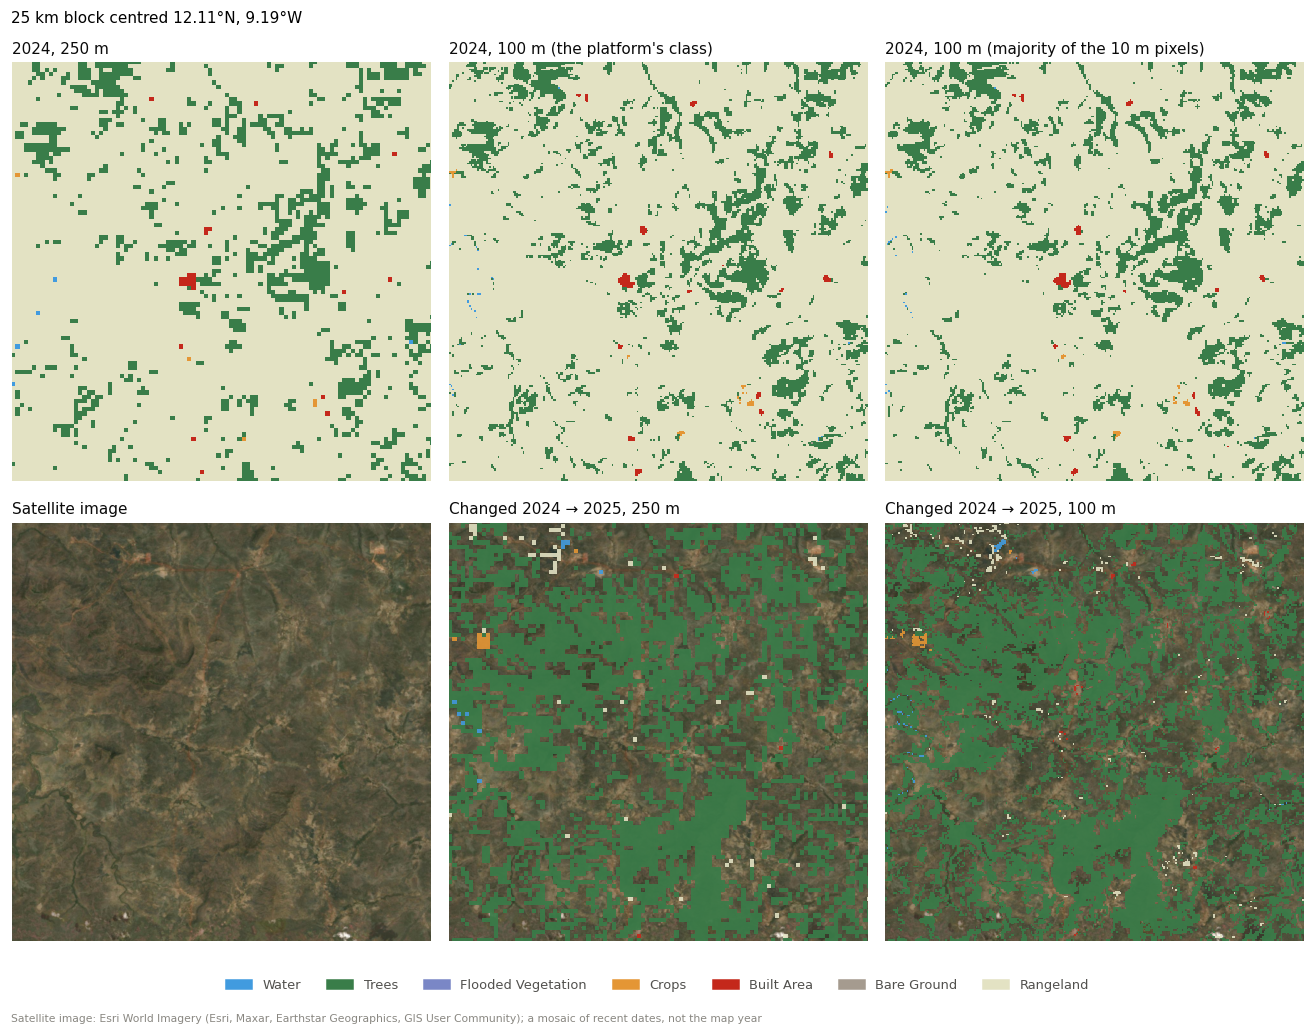

In [9]:
window = C.busiest_window()
maps = C.window_maps(window)
prof = G.profile()
fig, axes = plt.subplots(2, 3, figsize=(12, 9.4))
H.plot_classes(maps["250 m start"], "2024, 250 m", axes[0, 0])
axes[0, 0].images[0].set_extent(maps["250 m extent"])
H.plot_classes(maps["100 m start"], "2024, 100 m (the platform's class)", axes[0, 1])
H.plot_classes(maps["majority start"], "2024, 100 m (majority of the 10 m pixels)", axes[0, 2])
H.plot_satellite(axes[1, 0], prof, window, scale=4, title="Satellite image")
for ax, key, title in ((axes[1, 1], "250 m", "Changed 2024 → 2025, 250 m"), (axes[1, 2], "100 m", "Changed 2024 → 2025, 100 m")):
    H.plot_satellite(ax, prof, window, scale=4, title=title)
    ext = maps["250 m extent"] if key == "250 m" else (-0.5, window[2] - 0.5, window[2] - 0.5, -0.5)
    ax.imshow(C.changed_rgba(maps[f"{key} start"], maps[f"{key} end"]), extent=ext, interpolation="nearest")
for ax in axes.flat:
    ax.set_xlim(-0.5, window[2] - 0.5); ax.set_ylim(window[2] - 0.5, -0.5)
H.esri_class_legend(fig, C.CLASSES, loc="lower center", bbox_to_anchor=(0.5, 0.02))
lon, lat = G.lon_lat(np.array([(window[0] + window[2] // 2) * G.grid()["width"] + window[1] + window[2] // 2]))
fig.suptitle(f"25 km block centred {lat[0]:.2f}°N, {abs(lon[0]):.2f}°W", x=0.01, ha="left", fontsize=10)
H.satellite_credit(fig)
fig.subplots_adjust(left=0.01, right=0.99, top=0.93, bottom=0.08, wspace=0.04, hspace=0.1); plt.show()

**Reading:**

* **The platform's class and the majority of the 10 m pixels are hard to tell apart** (section 2).
* **The 250 m map draws coarser patches that do not sit exactly where the 100 m ones do**, the 13.5 % of cells where the two disagree (section 3).
* **On both grids the 2025 map turns most of this savanna block into trees**. The satellite image (a mosaic of recent dates) shows open savanna there. Most likely this is the flicker of section 4, a change in Esri's map rather than on the ground, which predictors cannot explain.

## 7 · What this means

* **The label stays the platform's class.** It is the majority of the 10 m pixels in 94.5 % of cells, and truly mixed cells are 0.4 %. Whether the shares help as extra inputs or training weights was not tested (notebook 05, section 9).
* **Class areas should come from the shares.** One class per cell undercounts crops and built area by 1 % and bare ground by 4 % at 100 m (4 %, 4 % and 13 % at 250 m). This is a suggestion for the platform, as for forest in the deforestation work.
* **Moving to 100 m does not reduce the flicker.** The maps change 10–15 % a year on both grids, and as much at 10 m; a quarter to two fifths of it flips back. The flip-back check stays.
* **The observed amount of change is the same in km² on both grids.** Under the deployed notebook's 1,000-pixel rule, 23 transitions qualify at 100 m against 12 at 250 m; the platform's backend trains every transition that occurs.
* **Scores at 100 m are compared with each other, not with 250 m scores.** The two maps agree in 86.5 % of cells. What carries over from 250 m is whether the ranking of the methods holds.
* **Next, notebook 02:** the predictors at 100 m, and the time and memory of the platform's run at 100 m on this laptop.

**Sources**

* Google Earth Engine. *Scale* (developer guide: image pyramids, and how a coarser scale is read). developers.google.com/earth-engine/guides/scale
* Moody, A., Woodcock, C.E. (1994). Scale-dependent errors in the estimation of land-cover proportions: implications for global land-cover datasets. *Photogrammetric Engineering and Remote Sensing* 60(5), 585–594.
* Pontius, R.G. Jr., Krithivasan, R., Sauls, L., Yan, Y., Zhang, Y. (2017). Methods to summarize change among land categories across time intervals. *Journal of Land Use Science* 12(4), 218–230.